На этом семинаре соберём двухэтапную рекомендательную систему на MovieLens-1M:

1. Разделим оценки по времени и посчитаем исторические признаки пользователей, фильмов и жанров.
2. Обучим CatBoostClassifier на положительных оценках и случайных популярных негативах.
3. Получим по кандидатов от ALS и TopPopular.
4. Объединим кандидатов двумя способами: Reciprocal Rank Fusion (RRF) и обученным CatBoost.
5. Сравним TopPopular, ALS, RRF и CatBoost между собой.

## 0. Установка и импорты

In [1]:
%pip install -q pandas numpy scipy scikit-learn matplotlib requests tqdm catboost implicit

In [2]:
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from catboost import CatBoostClassifier
from implicit.als import AlternatingLeastSquares
from IPython.display import display
from scipy.sparse import csr_matrix
from scipy.stats import rankdata
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DATA_DIR = Path('data/movielens')
DATA_DIR.mkdir(parents=True, exist_ok=True)

RETRIEVAL_K = 100
EVAL_K = 20
ALS_FACTORS = 48
ALS_ITERATIONS = 12
ALS_REGULARIZATION = 0.05
ALS_ALPHA = 20.0
NEGATIVES_PER_POSITIVE = 10
POPULARITY_EXPONENT = 0.75
NEGATIVE_POOL_TOP_N = 2_000
MAX_POS_PER_WINDOW = 20_000
MAX_POS_VAL = 15_000
MAX_POS_TEST = 15_000

## 1. Данные

[MovieLens-1M](https://grouplens.org/datasets/movielens/1m/) содержит оценки фильмов от 1 до 5, пользователей, время оценок и метаданные фильмов. Будем считать релевантными фильмы с оценкой 4–5. Оценки 1–3 тоже оставим в истории: они пригодятся для расчёта статистик и исключения уже оценённых фильмов.

Один фильм может иметь несколько жанров (`genres`). Например, `Action|Adventure|Sci-Fi`: при построении признаков будем учитывать все три.

In [25]:
def download(url: str, path: Path, chunk_size: int = 1 << 16) -> Path:
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.part')
    with requests.get(url, stream=True, timeout=60,
                      headers={'User-Agent': 'Mozilla/5.0'}) as response:
        response.raise_for_status()
        total = int(response.headers.get('content-length', 0))
        with open(temporary, 'wb') as fout, tqdm(
            total=total, unit='B', unit_scale=True, desc=path.name, leave=False
        ) as progress:
            for chunk in response.iter_content(chunk_size=chunk_size):
                if chunk:
                    fout.write(chunk)
                    progress.update(len(chunk))
    temporary.rename(path)
    return path


def download_and_unzip(url: str, root: Path, name: str) -> Path:
    folder = root / name
    if not (folder / 'ratings.dat').exists():
        archive = download(url, root / f'{name}.zip')
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(root)
    return folder


ml_dir = download_and_unzip(
    'https://files.grouplens.org/datasets/movielens/ml-1m.zip', DATA_DIR, 'ml-1m'
)
ratings = pd.read_csv(
    ml_dir / 'ratings.dat', sep='::', engine='python',
    names=['user_id', 'item_id', 'rating', 'timestamp']
)
movies = pd.read_csv(
    ml_dir / 'movies.dat', sep='::', engine='python', encoding='latin-1',
    names=['item_id', 'title', 'genres']
)
ratings['date'] = pd.to_datetime(ratings['timestamp'], unit='s', utc=True).dt.floor('D')
movies['genre_list'] = movies['genres'].fillna('').str.split('|')
movies['year'] = pd.to_numeric(
    movies['title'].str.extract(r'\((\d{4})\)\s*$')[0], errors='coerce'
)
print(f'Оценок: {len(ratings)}; пользователей: {ratings.user_id.nunique()}; '
      f'фильмов: {ratings.item_id.nunique()}')
display(ratings.head(), movies[['item_id', 'title', 'genres', 'year']].head())

Оценок: 1000209; пользователей: 6040; фильмов: 3706


,user_id,item_id,rating,timestamp,date
0,1,1193,5,978300760,2000-12-31 00:00:00+00:00
1,1,661,3,978302109,2000-12-31 00:00:00+00:00
2,1,914,3,978301968,2000-12-31 00:00:00+00:00
3,1,3408,4,978300275,2000-12-31 00:00:00+00:00
4,1,2355,5,978824291,2001-01-06 00:00:00+00:00


,item_id,title,genres,year
0,1,Toy Story (1995),Animation|Children's|Comedy,1995
1,2,Jumanji (1995),Adventure|Children's|Fantasy,1995
2,3,Grumpier Old Men (1995),Comedy|Romance,1995
3,4,Waiting to Exhale (1995),Comedy|Drama,1995
4,5,Father of the Bride Part II (1995),Comedy,1995


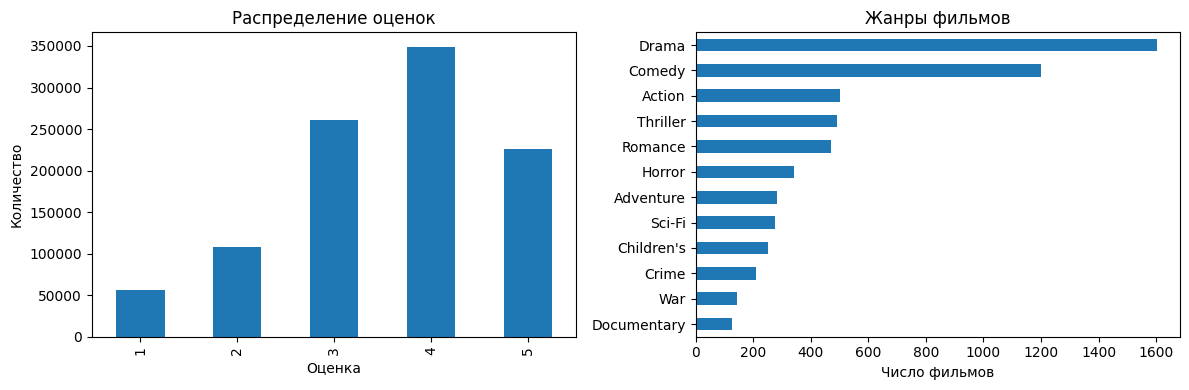

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings['rating'].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Количество')
movies.explode('genre_list')['genre_list'].value_counts().head(12).sort_values().plot.barh(ax=axes[1])
axes[1].set(title='Жанры фильмов', xlabel='Число фильмов', ylabel='')
plt.tight_layout()
plt.show()

## 2. Временное разбиение

Если случайно разделить оценки, в признаках пользователя или популярности фильма могут оказаться взаимодействия из будущего.

Поэтому сначала применим k-core=5, затем разобьём события глобально по времени примерно в пропорции 80% / 10% / 10% на train / validation / test. Для оценки используем warm start: оставим пользователей и фильмы, встречавшиеся в train.

Границы проводим по целым дням — позже будем считать условной сессией все оценки одного пользователя за дату `(user_id, date)`. В validation используем только историю из train, в test — историю из train + validation.

In [29]:
def iterative_k_core(df: pd.DataFrame, k: int = 5) -> pd.DataFrame:
    result = df.copy()
    while True:
        previous = len(result)
        result = result.loc[result.groupby('user_id')['item_id'].transform('size') >= k].copy()
        result = result.loc[result.groupby('item_id')['user_id'].transform('size') >= k].copy()
        if len(result) == previous:
            return result.reset_index(drop=True)


def global_temporal_split(df: pd.DataFrame, val_ratio: float = 0.1, test_ratio: float = 0.1):
    first = pd.to_datetime(
        df['timestamp'].quantile(1 - val_ratio - test_ratio, interpolation='nearest'),
        unit='s', utc=True
    ).floor('D')
    second = pd.to_datetime(
        df['timestamp'].quantile(1 - test_ratio, interpolation='nearest'),
        unit='s', utc=True
    ).floor('D')
    assert first < second
    return (
        df.loc[df['date'] < first].copy().reset_index(drop=True),
        df.loc[(df['date'] >= first) & (df['date'] < second)].copy().reset_index(drop=True),
        df.loc[df['date'] >= second].copy().reset_index(drop=True),
    )


def warm_start(part: pd.DataFrame, history: pd.DataFrame) -> pd.DataFrame:
    return part.loc[
        part['user_id'].isin(history['user_id']) &
        part['item_id'].isin(history['item_id'])
    ].copy().reset_index(drop=True)


filtered = iterative_k_core(ratings, k=5)
train, val_raw, test_raw = global_temporal_split(filtered)
val = warm_start(val_raw, train)
test = warm_start(test_raw, train)
train_val = pd.concat([train, val], ignore_index=True)
assert len(train) and len(val) and len(test)
assert train['date'].max() < val['date'].min()
assert val['date'].max() < test['date'].min()

split_stats = pd.DataFrame([
    {'period': name, 'events': len(part), 'users': part.user_id.nunique(),
     'items': part.item_id.nunique(), 'positives (4–5)': int((part.rating >= 4).sum()),
     'start': part.date.min().date(), 'end': part.date.max().date()}
    for name, part in [('train', train), ('val', val), ('test', test)]
])
display(split_stats)

,period,events,users,items,positives (4–5),start,end
0,train,796690,5390,3411,460932,2000-04-25,2000-12-01
1,val,25437,530,2971,13677,2000-12-02,2000-12-28
2,test,80471,1006,3283,43417,2000-12-29,2003-02-28


## 3. Исторические признаки

Популярность фильма сама по себе не отвечает на вопрос, понравится ли он конкретному пользователю. Хотим описать и общие свойства фильма, и предпочтения пользователя, причём *только на начало оцениваемого периода*.

Насчитаем следующие 15 признаков:

| Группа | Признаки | Что отражают |
|---|---|---|
| User | `user_count`, `user_mean_rating`, `user_like_rate`, `user_recent_90d` | Активность и склонность ставить высокие оценки |
| Item | `item_count`, `item_mean_rating`, `item_bayes_like_rate`, `item_recent_90d` | Популярность, качество и свежий интерес |
| Жанры / метаданные фильма | `movie_age`, `movie_n_genres`, `genre_avg_popularity`, `genre_avg_like_rate` | Возраст, жанровый состав и общую востребованность жанров |
| User × genre | `user_genre_share`, `user_genre_like_rate`, `user_genre_recent_share` | Насколько жанры фильма близки пользователю |

У фильма может быть несколько жанров: учитываем каждый из них.

Долю положительных оценок фильма сгладим, чтобы несколько пятёрок у малоизвестного фильма не давали слишком большой скор:

$$\operatorname{smoothed\_like\_rate}(i)=\frac{L_i+m\bar p}{N_i+m}, \qquad m=20,$$

где $L_i$ — число оценок 4–5, $N_i$ — число оценок фильма, а $\bar p$ — доля оценок 4–5 по накопленной истории.

In [30]:
GENRES = sorted({genre for genres in movies['genre_list'] for genre in genres if genre})
N_USERS = int(ratings.user_id.max()) + 1
N_ITEMS = int(max(ratings.item_id.max(), movies.item_id.max())) + 1

# Один фильм может принадлежать нескольким жанрам.
ITEM_GENRES = np.zeros((N_ITEMS, len(GENRES)), dtype=np.float32)
ITEM_YEAR = np.full(N_ITEMS, float(movies['year'].median()), dtype=np.float32)
for movie in movies.itertuples(index=False):
    ITEM_GENRES[int(movie.item_id)] = [float(g in movie.genre_list) for g in GENRES]
    if pd.notna(movie.year):
        ITEM_YEAR[int(movie.item_id)] = float(movie.year)
GENRE_SPARSE = csr_matrix(ITEM_GENRES)

FEATURE_COLUMNS = [
    'user_count', 'user_mean_rating', 'user_like_rate', 'user_recent_90d',
    'item_count', 'item_mean_rating', 'item_bayes_like_rate', 'item_recent_90d',
    'movie_age', 'movie_n_genres', 'genre_avg_popularity', 'genre_avg_like_rate',
    'user_genre_share', 'user_genre_like_rate', 'user_genre_recent_share',
]
print('Признаков:', len(FEATURE_COLUMNS), '| жанров MovieLens:', len(GENRES))

Признаков: 15 | жанров MovieLens: 18


In [31]:
def snapshot(history: pd.DataFrame, asof: pd.Timestamp) -> dict:
    """Вычисляет статистики, известные к началу периода asof."""
    assert not history.empty
    assert history['timestamp'].max() < int(asof.timestamp())

    u = history['user_id'].to_numpy(dtype=np.int32)
    i = history['item_id'].to_numpy(dtype=np.int32)
    r = history['rating'].to_numpy(dtype=np.float32)
    liked = (r >= 4).astype(np.float32)
    recent = (history['timestamp'].to_numpy() >= int(asof.timestamp()) - 90 * 86400).astype(np.float32)

    def aggregate(ids, values, size):
        return np.bincount(ids, weights=values, minlength=size).astype(np.float32)

    uc = aggregate(u, np.ones(len(u)), N_USERS)
    ic = aggregate(i, np.ones(len(i)), N_ITEMS)
    ul = aggregate(u, liked, N_USERS)
    il = aggregate(i, liked, N_ITEMS)

    shape = (N_USERS, N_ITEMS)
    def user_genres(values):
        interactions = csr_matrix((values, (u, i)), shape=shape)
        return (interactions @ GENRE_SPARSE).toarray().astype(np.float32)

    genre_count = ic @ ITEM_GENRES
    genre_likes = il @ ITEM_GENRES

    return {
        'user_count': uc,
        'user_mean_rating': aggregate(u, r, N_USERS) / np.maximum(uc, 1),
        'user_like_rate': ul / np.maximum(uc, 1),
        'user_recent_90d': aggregate(u, recent, N_USERS),
        'item_count': ic,
        'item_like_count': il,
        'item_mean_rating': aggregate(i, r, N_ITEMS) / np.maximum(ic, 1),
        'item_recent_90d': aggregate(i, recent, N_ITEMS),
        'global_like_rate': float(liked.mean()),
        'genre_count': genre_count,
        'genre_like_rate': genre_likes / np.maximum(genre_count, 1),
        'ug_count': user_genres(np.ones(len(u), dtype=np.float32)),
        'ug_like': user_genres(liked),
        'ug_recent': user_genres(recent),
        'asof': asof,
    }


def add_features(pairs: pd.DataFrame, s: dict) -> pd.DataFrame:
    result = pairs.copy()
    u = result['user_id'].to_numpy(dtype=np.int32)
    i = result['item_id'].to_numpy(dtype=np.int32)

    mask = ITEM_GENRES[i]  # Все жанры каждого кандидата.
    n_genres = np.maximum(mask.sum(axis=1), 1)
    ug = s['ug_count'][u]
    ug_likes = s['ug_like'][u]
    ug_recent = s['ug_recent'][u]
    matched = (ug * mask).sum(axis=1)

    values = {
        'user_count': s['user_count'][u],
        'user_mean_rating': s['user_mean_rating'][u],
        'user_like_rate': s['user_like_rate'][u],
        'user_recent_90d': s['user_recent_90d'][u],
        'item_count': s['item_count'][i],
        'item_mean_rating': s['item_mean_rating'][i],
        'item_bayes_like_rate': (s['item_like_count'][i] + 20 * s['global_like_rate']) /
                                (s['item_count'][i] + 20),
        'item_recent_90d': s['item_recent_90d'][i],
        'movie_age': np.maximum(s['asof'].year - ITEM_YEAR[i], 0),
        'movie_n_genres': mask.sum(axis=1),
        'genre_avg_popularity': (mask @ s['genre_count']) / n_genres,
        'genre_avg_like_rate': (mask @ s['genre_like_rate']) / n_genres,
        'user_genre_share': matched / np.maximum(ug.sum(axis=1), 1),
        'user_genre_like_rate': (ug_likes * mask).sum(axis=1) / np.maximum(matched, 1),
        'user_genre_recent_share': (ug_recent * mask).sum(axis=1) /
                                    np.maximum(ug_recent.sum(axis=1), 1),
    }
    for name in FEATURE_COLUMNS:
        result[name] = np.asarray(values[name], dtype=np.float32)

    assert np.isfinite(result[FEATURE_COLUMNS].to_numpy()).all()

    return result

## 4. Обучающая выборка

В MovieLens есть оценки, но нет логов показов. Для обучения классификатора нужны пары «пользователь–фильм» обоих классов. Положительными примерами возьмём оценки 4–5, отрицательными — случайно выбранные неоценённые на момент сессии фильмы. Это *псевдонегативы*.

На каждый позитив возьмём 10 негативов. Вместо равномерной выборки из всего каталога будем чаще выбирать популярные фильмы: различать их с позитивами сложнее. Сначала возьмем до 2000 наиболее популярных объектов из предшествующей истории, затем выбираем из доступных фильмов без повторов с вероятностями

$$
P(i\mid u,t) = \frac{(n_i+1)^{\beta}}{\sum_{j \in I^-_{u,t}}(n_j+1)^{\beta}}, \qquad \beta=0.75,
$$

где $n_i$ — количество исторических оценок фильма, а $I^-_{u,t}$ — доступный пул фильмов для пользователя $u$ на дату $t$. Если в популярных фильмах не хватает объектов, расширим пул до всего исторически известного каталога.

Для train построим несколько последовательных окон: признаки каждого окна считаем по предшествующей истории, позитивы берём из следующего окна. Для validation признаки считаем по train, для test — по train + validation. Количество позитивов ограничим, чтобы эксперимент оставался компактным.

In [32]:
def train_windows(df: pd.DataFrame, n_windows: int = 4) -> list[pd.DataFrame]:
    boundaries = sorted({pd.to_datetime(
        df['timestamp'].quantile(j / n_windows, interpolation='nearest'), unit='s', utc=True
    ).floor('D') for j in range(1, n_windows)})
    result = []
    left = df['date'].min()
    for right in boundaries:
        part = df.loc[(df['date'] >= left) & (df['date'] < right)].copy()
        if not part.empty:
            result.append(part)
        left = right
    last = df.loc[df['date'] >= left].copy()
    if not last.empty:
        result.append(last)
    assert len(result) >= 2
    return result


def sample_ranking_rows(history: pd.DataFrame, target: pd.DataFrame, stats: dict,
                        max_positives: int, seed: int) -> pd.DataFrame:
    """Позитивы и популярные псевдонегативы без доступа к будущим дням."""
    assert not history.empty and not target.empty
    assert history['timestamp'].max() < int(target['date'].min().timestamp())

    positives = target.loc[target['rating'] >= 4, ['user_id', 'item_id', 'date']].drop_duplicates()
    positives = positives.loc[
        positives['user_id'].isin(history['user_id']) &
        positives['item_id'].isin(history['item_id'])
    ]
    if len(positives) > max_positives:
        positives = positives.sample(n=max_positives, random_state=seed)

    catalog = np.sort(history['item_id'].unique().astype(np.int32))
    popularity = stats['item_count'][catalog]
    top_indices = np.argsort(-popularity, kind='stable')[:NEGATIVE_POOL_TOP_N]
    popular_catalog = catalog[top_indices]

    history_seen = history.groupby('user_id')['item_id'].agg(set).to_dict()
    # Список позитивов для каждой сессии; сессии без позитива тоже меняют историю просмотров.
    positive_sessions = {
        (int(uid), date): group
        for (uid, date), group in positives.groupby(['user_id', 'date'], sort=False)
    }
    known_items = {int(uid): set(items) for uid, items in history_seen.items()}

    rows = []
    # Сессии идут по датам внутри каждого пользователя. Для текущей даты видим
    # только оценки предыдущих дней и оценки текущей сессии.
    for (uid, date), day_events in target.groupby(['user_id', 'date'], sort=True):
        uid = int(uid)
        seen = known_items.setdefault(uid, set())
        seen.update(day_events['item_id'].astype(int))
        group = positive_sessions.get((uid, date))
        if group is None:
            continue

        # Отдельный генератор для каждой (user_id, date): будущие сессии других
        # пользователей не меняют негативы для этой сессии.
        day_number = int(date.timestamp() // 86400)
        session_rng = np.random.default_rng(
            np.random.SeedSequence([int(seed), uid, day_number])
        )
        expected_negatives = NEGATIVES_PER_POSITIVE * len(group)
        excluded = np.fromiter(seen, dtype=np.int32)
        pool = popular_catalog[~np.isin(popular_catalog, excluded)]
        if len(pool) < expected_negatives:
            pool = catalog[~np.isin(catalog, excluded)]

        # Если уникальных фильмов мало, уменьшаем число позитивов в сессии:
        # это сохраняет строго 10 различных негативов на каждый позитив.
        max_positives = len(pool) // NEGATIVES_PER_POSITIVE
        if max_positives == 0:
            continue
        if len(group) > max_positives:
            chosen_rows = session_rng.choice(len(group), size=max_positives, replace=False)
            group = group.iloc[np.sort(chosen_rows)]
        expected_negatives = NEGATIVES_PER_POSITIVE * len(group)
        weights = np.power(stats['item_count'][pool] + 1.0, POPULARITY_EXPONENT)
        weights /= weights.sum()
        selected = session_rng.choice(pool, size=expected_negatives,
                                      replace=False, p=weights)

        good = group.copy()
        good['label'] = 1
        bad = pd.DataFrame({
            'user_id': uid, 'item_id': selected, 'date': date, 'label': 0
        })
        rows.extend([good, bad])

    if not rows:
        raise ValueError('Недостаточно позитивов с историей и доступных негативов')
    result = pd.concat(rows, ignore_index=True)
    result['session_id'] = (
        result['date'].dt.strftime('%Y-%m-%d') + '_' + result['user_id'].astype(str)
    )
    assert not result.duplicated(['session_id', 'item_id']).any()
    assert result.groupby('session_id')['label'].nunique().eq(2).all()
    by_session = result.groupby(['session_id', 'label']).size().unstack(fill_value=0)
    assert (by_session[0] == NEGATIVES_PER_POSITIVE * by_session[1]).all()
    return result


In [33]:
windows = train_windows(train)
rank_parts = []
for j in range(1, len(windows)):
    history = pd.concat(windows[:j], ignore_index=True)
    target = warm_start(windows[j], history)
    if target.empty or not (target.rating >= 4).any():
        continue
    asof = target['date'].min()
    assert history['timestamp'].max() < int(asof.timestamp())
    print(f'Окно {j}/{len(windows)-1}: история до {asof.date()}')
    stats_w = snapshot(history, asof)
    sampled_w = sample_ranking_rows(history, target, stats_w,
                                    MAX_POS_PER_WINDOW, SEED + j)
    rank_parts.append(add_features(sampled_w, stats_w))
    print(f'  позитивов: {sampled_w.label.sum():,}, негативов: '
          f'{(sampled_w.label == 0).sum():,}, сессий: {sampled_w.session_id.nunique():,}')

rank_train = pd.concat(rank_parts, ignore_index=True)
print('Train CatBoost:', len(rank_train), 'строк,', rank_train.session_id.nunique(), 'сессий')
print(f'Негативов на позитив: {(rank_train.label == 0).sum() / rank_train.label.sum():.2f}')
display(rank_train[['session_id', 'user_id', 'item_id', 'label',
                    'item_count', 'user_genre_share']].head())

Окно 1/3: история до 2000-07-20
  позитивов: 3,502, негативов: 35,020, сессий: 342
Окно 2/3: история до 2000-08-29
  позитивов: 10,092, негативов: 100,920, сессий: 876
Окно 3/3: история до 2000-11-20
  позитивов: 5,336, негативов: 53,360, сессий: 329
Train CatBoost: 208230 строк, 1547 сессий
Негативов на позитив: 10.00


,session_id,user_id,item_id,label,item_count,user_genre_share
0,2000-07-20_4628,4628,3408,1,176.0,0.263158
1,2000-07-20_4628,4628,2861,1,91.0,0.473684
2,2000-07-20_4628,4628,2396,1,571.0,0.263158
3,2000-07-20_4628,4628,2757,1,30.0,0.263158
4,2000-07-20_4628,4628,2762,1,670.0,0.157895


Посмотрим на одну обучающую сессию. У неё есть положительные фильмы с оценками 4–5 и десять случайных популярных псевдонегативов на каждый позитив. Одна строка таблицы — один фильм-кандидат, а не один пользователь.

In [34]:
example_session = rank_train['session_id'].iloc[0]
example_rows = rank_train.loc[rank_train.session_id == example_session]
display(example_rows[[
    'session_id', 'item_id', 'label', 'user_count',
    'item_count', 'user_genre_share', 'user_genre_like_rate'
]].head(15))

,session_id,item_id,label,user_count,item_count,user_genre_share,user_genre_like_rate
0,2000-07-20_4628,3408,1,12.0,176.0,0.263158,0.400000
1,2000-07-20_4628,2861,1,12.0,91.0,0.473684,0.333333
2,2000-07-20_4628,2396,1,12.0,571.0,0.263158,0.200000
3,2000-07-20_4628,2757,1,12.0,30.0,0.263158,0.400000
4,2000-07-20_4628,2762,1,12.0,670.0,0.157895,0.666667
5,2000-07-20_4628,293,0,12.0,178.0,0.578947,0.545455
6,2000-07-20_4628,1367,0,12.0,78.0,0.210526,0.250000
7,2000-07-20_4628,1374,0,12.0,315.0,0.052632,1.000000
8,2000-07-20_4628,1093,0,12.0,135.0,0.263158,0.400000
9,2000-07-20_4628,76,0,12.0,33.0,0.157895,0.666667


## 5. CatBoostClassifier и GAUC

Теперь для каждой пары $(u,i)$ есть признаки $x_{ui}$ и метка $y_{ui}\in\{0,1\}$. Обучим `CatBoostClassifier` предсказывать $P(y_{ui}=1\mid x_{ui})$; внутри одного запроса сортируем фильмы по этой вероятности.

Для проверки того, насколько хорошо модель различает положительные фильмы и сэмплированные негативы, используем GAUC: сначала считаем AUC внутри каждой сессии `(user_id, date)`, затем усредняем по размеру сессии:

$$\mathrm{GAUC}=\frac{\sum_{s}|s|\,\mathrm{AUC}_s}{\sum_s |s|}.$$

Сессии с одним классом пропускаем. Бейзлайн — опулярность по числу положительных исторических оценок фильма. Обе модели проверяем на одинаковых строках validation.

In [35]:
val_stats = snapshot(train, val['date'].min())
rank_val_raw = sample_ranking_rows(train, val, val_stats, MAX_POS_VAL, SEED + 100)
rank_val = add_features(rank_val_raw, val_stats)
print(f'Validation: {len(rank_val):,} примеров, '
      f'{rank_val.session_id.nunique():,} условных сессий')
print(f'Негативов на позитив в validation: '
      f'{(rank_val.label == 0).sum() / rank_val.label.sum():.2f}')

Validation: 148,599 примеров, 908 условных сессий
Негативов на позитив в validation: 10.00


In [36]:
def gauc(data: pd.DataFrame, score) -> tuple[float, int]:
    frame = data[['session_id', 'label']].copy()
    frame['score'] = np.asarray(score)
    weighted_auc, total, sessions = 0.0, 0, 0
    for _, part in frame.groupby('session_id', sort=False):
        label = part['label'].to_numpy()
        positive_count = int(label.sum())
        negative_count = len(label) - positive_count
        if positive_count == 0 or negative_count == 0:
            continue
        ranks = rankdata(part['score'].to_numpy(), method='average')
        auc = ((ranks[label == 1].sum() - positive_count * (positive_count + 1) / 2)
               / (positive_count * negative_count))
        weighted_auc += auc * len(part)
        total += len(part)
        sessions += 1
    return weighted_auc / total if total else float('nan'), sessions


ranker = CatBoostClassifier(
    iterations=500, depth=6, learning_rate=0.03, l2_leaf_reg=5,
    loss_function='Logloss', eval_metric='AUC', random_seed=SEED,
    thread_count=4, verbose=False, allow_writing_files=False
)
ranker.fit(
    rank_train[FEATURE_COLUMNS], rank_train['label'],
    eval_set=(rank_val[FEATURE_COLUMNS], rank_val['label']),
    early_stopping_rounds=40, verbose=False
)
val_scores = ranker.predict_proba(rank_val[FEATURE_COLUMNS])[:, 1]
val_cat_gauc, val_sessions = gauc(rank_val, val_scores)
val_pop_gauc, _ = gauc(rank_val, val_stats['item_like_count'][rank_val['item_id'].to_numpy(dtype=np.int32)])
val_gauc_table = pd.DataFrame([
    {'model': 'TopPopular (положительные оценки)', 'GAUC': val_pop_gauc},
    {'model': 'CatBoostClassifier', 'GAUC': val_cat_gauc}
])
display(val_gauc_table)

,model,GAUC
0,TopPopular (положительные оценки),0.682064
1,CatBoostClassifier,0.711279


Посмотрим на конкретную сессию. `CatBoost` выдаёт скор каждой строке; сортировка по скору превращает классификатор в pointwise-ранжировщик.

In [37]:
example_session = rank_val['session_id'].iloc[0]
example = rank_val.loc[rank_val.session_id == example_session].copy()
example['catboost_score'] = ranker.predict_proba(example[FEATURE_COLUMNS])[:, 1]
example['popularity'] = val_stats['item_like_count'][example.item_id.to_numpy(dtype=np.int32)]
example['title'] = example.item_id.map(movies.set_index('item_id')['title'])
display(example.sort_values('catboost_score', ascending=False)[
    ['title', 'label', 'catboost_score', 'popularity', 'user_genre_share']
].head(15))

,title,label,catboost_score,popularity,user_genre_share
4,"Silence of the Lambs, The (1991)",1,0.429924,1880.0,0.636364
15,American Beauty (1999),1,0.427974,2418.0,0.545455
372,Schindler's List (1993),0,0.415380,1730.0,0.545455
335,Pulp Fiction (1994),0,0.412151,1473.0,0.545455
338,Good Will Hunting (1997),0,0.395009,993.0,0.454545
17,Fargo (1996),1,0.393541,1768.0,0.727273
159,Gladiator (2000),0,0.378670,1057.0,0.545455
30,GoodFellas (1990),1,0.374813,1151.0,0.545455
118,One Flew Over the Cuckoo's Nest (1975),0,0.365302,1256.0,0.454545
376,"Fugitive, The (1993)",0,0.364298,1349.0,0.272727


### Важность признаков

В деревьях можно посмотреть, какие признаки сильнее меняют прогноз (`PredictionValuesChange`). Сравним общие признаки популярности фильма и персональные жанровые признаки: что оказалось полезнее для нашей обучающей выборки?

,feature,importance
5,item_mean_rating,13.222397
6,item_bayes_like_rate,13.190586
7,item_recent_90d,11.326459
2,user_like_rate,8.958514
4,item_count,8.615780
8,movie_age,8.527462
1,user_mean_rating,6.619327
3,user_recent_90d,6.007381
0,user_count,5.605356
13,user_genre_like_rate,4.187383


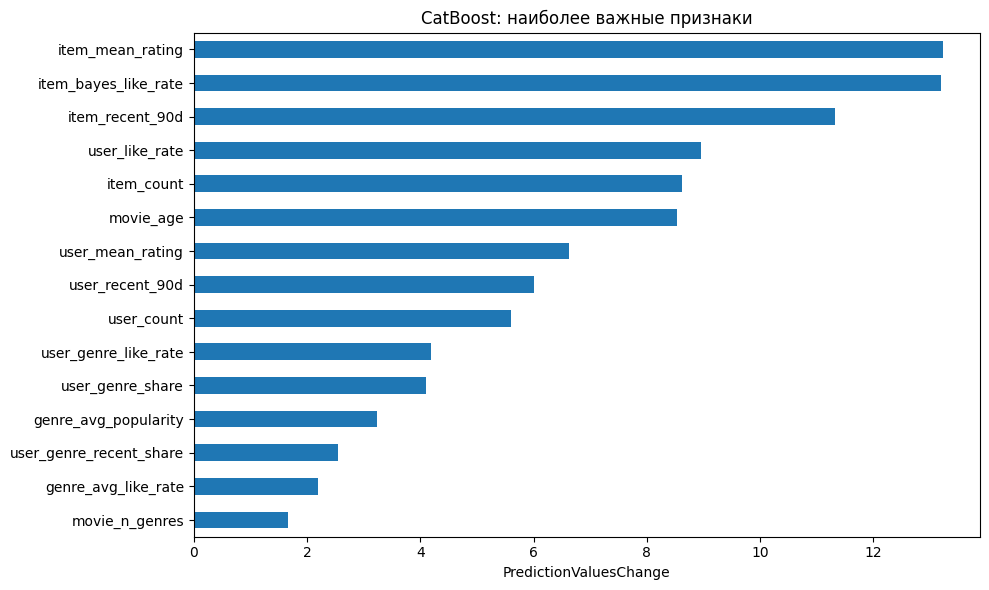

In [38]:
importance = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'importance': ranker.get_feature_importance()
}).sort_values('importance', ascending=False)
display(importance.head(15))
fig, ax = plt.subplots(figsize=(10, 6))
importance.head(15).iloc[::-1].plot.barh(x='feature', y='importance', ax=ax, legend=False)
ax.set(title='CatBoost: наиболее важные признаки', xlabel='PredictionValuesChange', ylabel='')
plt.tight_layout()
plt.show()

## 6. Кандидатогенерация: ALS и TopPopular

В настоящем рекомендательном пайплайне CatBoost не обязан сравнивать все фильмы каталога: сначала более дешёвые алгоритмы формируют небольшой пул кандидатов.

- TopPopular сортирует фильмы по числу положительных оценок в истории.
- ALS раскладывает матрицу положительных взаимодействий на факторы пользователей и фильмов; приблизительный скор пары — $\langle p_u,q_i\rangle$.

Пусть модель рекомендует до 100 фильмов, исключая все уже оценённые пользователем. На validation обучаем их на train, на test — на train + validation.

In [39]:
class TopPopular:
    def __init__(self, history: pd.DataFrame):
        liked = history.loc[history['rating'] >= 4]
        self.items = (liked.groupby('item_id').size()
                      .sort_values(ascending=False, kind='stable').index.to_numpy(dtype=np.int32))
        self.seen = history.groupby('user_id')['item_id'].agg(set).to_dict()

    def recommend(self, users, k: int = 100) -> dict[int, list[int]]:
        result = {}
        for uid in users:
            uid = int(uid)
            seen = self.seen.get(uid, set())
            result[uid] = [int(item) for item in self.items if int(item) not in seen][:k]
        return result


class ALS:
    def __init__(self, history: pd.DataFrame, factors: int = ALS_FACTORS,
                 iterations: int = ALS_ITERATIONS, regularization: float = ALS_REGULARIZATION,
                 alpha: float = ALS_ALPHA, seed: int = SEED):
        liked = history.loc[history['rating'] >= 4]
        self.seen = history.groupby('user_id')['item_id'].agg(set).to_dict()
        self.users = np.sort(liked['user_id'].unique())
        self.items = np.sort(liked['item_id'].unique())
        self.u_index = {int(uid): j for j, uid in enumerate(self.users)}
        self.i_index = {int(iid): j for j, iid in enumerate(self.items)}
        row = liked['user_id'].map(self.u_index).to_numpy()
        col = liked['item_id'].map(self.i_index).to_numpy()
        weights = 1 + alpha * (liked['rating'].to_numpy(dtype=np.float32) - 3)
        matrix = csr_matrix((weights, (row, col)), shape=(len(self.users), len(self.items)))
        self.model = AlternatingLeastSquares(
            factors=factors, iterations=iterations,
            regularization=regularization, random_state=seed
        )
        self.model.fit(matrix)

    def recommend(self, users, k: int = 100, batch_size: int = 256) -> dict[int, list[int]]:
        result = {int(uid): [] for uid in users}
        active = [int(uid) for uid in users if int(uid) in self.u_index]
        for start in range(0, len(active), batch_size):
            batch = active[start:start + batch_size]
            ids = np.array([self.u_index[u] for u in batch])
            scores = self.model.user_factors[ids] @ self.model.item_factors.T
            for j, uid in enumerate(batch):
                seen_indices = [self.i_index[iid] for iid in self.seen.get(uid, set())
                                if iid in self.i_index]
                scores[j, seen_indices] = -np.inf
                eligible = np.flatnonzero(np.isfinite(scores[j]))
                if not len(eligible):
                    continue
                count = min(k, len(eligible))
                local = np.argpartition(-scores[j, eligible], count - 1)[:count]
                selected = eligible[local]
                selected = selected[np.argsort(-scores[j, selected], kind='stable')]
                result[uid] = [int(self.items[index]) for index in selected]
        return result


def union_frame(als_recs: dict, popular_recs: dict) -> pd.DataFrame:
    rows = []
    for uid in sorted(set(als_recs) | set(popular_recs)):
        # dict.fromkeys сохраняет порядок и удаляет повторы.
        union = dict.fromkeys(als_recs.get(uid, []) + popular_recs.get(uid, []))
        rows.extend((int(uid), int(iid)) for iid in union)
    result = pd.DataFrame(rows, columns=['user_id', 'item_id'])
    assert not result.duplicated(['user_id', 'item_id']).any()
    return result


In [40]:
def candidates_from_history(history: pd.DataFrame, target: pd.DataFrame):
    users = sorted(set(target['user_id']) & set(history['user_id']))
    top = TopPopular(history)
    als = ALS(history)
    top100 = top.recommend(users, RETRIEVAL_K)
    als100 = als.recommend(users, RETRIEVAL_K)
    return als100, top100, union_frame(als100, top100)

In [41]:
val_truth = val.loc[val.rating >= 4].groupby('user_id')['item_id'].agg(set).to_dict()
val_users = sorted(val_truth)
val_als100, val_top100, val_union = candidates_from_history(train, val.loc[val.rating >= 4])
print(f'Validation: ALS и TopPopular предложили {len(val_union):,} уникальных пар '
      f'для {len(val_users):,} пользователей')
display(val_union.head())

  0%|          | 0/12 [00:00<?, ?it/s]

Validation: ALS и TopPopular предложили 82,441 уникальных пар для 499 пользователей


,user_id,item_id
0,645,858
1,645,1221
2,645,593
3,645,2858
4,645,608


## 7. Объединяем кандидатов без обучения: RRF

ALS и TopPopular могут выдавать скоры в разных масштабах. Складывать их напрямую неудобно. Reciprocal Rank Fusion использует только место фильма в списке каждого источника:

$$\mathrm{RRF}(u,i)=\sum_{m\in\{\mathrm{ALS},\mathrm{TopPopular}\}}\frac{1}{c+\mathrm{rank}_m(u,i)},\qquad c=60.$$

Если фильма нет в выдаче источника, тот источник не добавляет слагаемого.

In [42]:
def reciprocal_rank_fusion(als_recs: dict, popular_recs: dict,
                           k: int = 20, c: int = 60) -> dict[int, list[int]]:
    result = {}
    for uid in sorted(set(als_recs) | set(popular_recs)):
        scores = {}
        for recs in (als_recs.get(uid, []), popular_recs.get(uid, [])):
            for rank, item in enumerate(recs, start=1):
                scores[item] = scores.get(item, 0.0) + 1.0 / (c + rank)
        result[int(uid)] = sorted(scores, key=lambda item: (-scores[item], item))[:k]
    return result


val_rrf20 = reciprocal_rank_fusion(val_als100, val_top100, k=EVAL_K)
val_overlap = [len(set(val_als100.get(uid, [])) & set(val_top100.get(uid, [])))
               for uid in val_truth]
print(f'Среднее пересечение двух топ-100: {np.mean(val_overlap):.1f} фильма')
print('RRF для первого пользователя:', val_rrf20[sorted(val_truth)[0]][:10])

Среднее пересечение двух топ-100: 34.8 фильма
RRF для первого пользователя: [2858, 593, 858, 608, 260, 527, 1196, 2762, 1198, 1617]


## 8. HitRate@20 и NDCG@20

GAUC проверяла CatBoost на сэмплированных парах, а теперь нас интересует готовый топ-20. Пусть $R_u$ — выдача модели, $T_u$ — множество всех фильмов с оценкой 4–5 у пользователя в отложенном периоде.

$$\mathrm{HitRate@20}=\frac{1}{|U|}\sum_u \mathbb{1}[R_u[:20]\cap T_u\neq\varnothing].$$

$$\mathrm{NDCG@20}=\frac{1}{|U|}\sum_u\frac{\sum_{j=1}^{20}\mathbb{1}[R_u[j]\in T_u]/\log_2(j+1)}{\sum_{j=1}^{\min(20,|T_u|)}1/\log_2(j+1)}.$$

Оцениваем пользователей, имеющих хотя бы одну положительную оценку в отложенном периоде. В знаменателе NDCG учитываем все их положительные фильмы, в том числе отсутствующие среди кандидатов. Сравниваем TopPopular@20, ALS@20, RRF@20 и CatBoost@20 на одном ground truth.

In [43]:
def ground_truth(df: pd.DataFrame) -> dict[int, set[int]]:
    return df.loc[df.rating >= 4].groupby('user_id')['item_id'].agg(set).to_dict()


def evaluate_at_k(recs: dict, truth: dict, k: int = 20) -> dict:
    discounts = 1 / np.log2(np.arange(2, k + 2))
    hits, ndcgs = [], []
    for uid, relevant in truth.items():
        items = recs.get(int(uid), [])[:k]
        correct = np.array([int(item in relevant) for item in items], dtype=float)
        hits.append(float(correct.any()))
        dcg = float(np.dot(correct, discounts[:len(correct)]))
        idcg = float(discounts[:min(k, len(relevant))].sum())
        ndcgs.append(dcg / idcg if idcg else 0)
    return {'HitRate@20': float(np.mean(hits)), 'NDCG@20': float(np.mean(ndcgs)),
            'users': len(hits)}


def rerank(model: CatBoostClassifier, candidates: pd.DataFrame, stats: dict,
           k: int = 20, user_batch: int = 250) -> dict[int, list[int]]:
    recs = {}
    users = candidates['user_id'].drop_duplicates().tolist()
    indexed = candidates.set_index('user_id', drop=False)
    for start in tqdm(range(0, len(users), user_batch), desc='Re-ranking', leave=False):
        block = users[start:start + user_batch]
        batch = indexed.loc[block].reset_index(drop=True)
        featured = add_features(batch, stats)
        featured['score'] = model.predict_proba(featured[FEATURE_COLUMNS])[:, 1]
        featured = featured.sort_values(['user_id', 'score', 'item_id'],
                                        ascending=[True, False, True])
        for uid, group in featured.groupby('user_id', sort=False):
            recs[int(uid)] = group['item_id'].head(k).astype(int).tolist()
    return recs


def candidate_hitrate(candidates: pd.DataFrame, truth: dict) -> float:
    found = candidates.groupby('user_id')['item_id'].agg(set).to_dict()
    return float(np.mean([bool(found.get(uid, set()) & relevant)
                          for uid, relevant in truth.items()]))


def compare_models(popular: dict, als: dict, rrf: dict,
                   reranked: dict, truth: dict) -> pd.DataFrame:
    return pd.DataFrame([
        {'model': name, **evaluate_at_k(items, truth, EVAL_K)}
        for name, items in [
            ('TopPopular', popular), ('ALS', als),
            ('ALS + TopPopular → RRF', rrf),
            ('ALS + TopPopular → CatBoost', reranked),
        ]
    ])

In [44]:
val_reranked20 = rerank(ranker, val_union, val_stats, EVAL_K)
val_table = compare_models(val_top100, val_als100, val_rrf20, val_reranked20, val_truth)
display(val_table.sort_values('NDCG@20', ascending=False))

Re-ranking:   0%|          | 0/2 [00:00<?, ?it/s]

,model,HitRate@20,NDCG@20,users
3,ALS + TopPopular → CatBoost,0.595190,0.151315,499
2,ALS + TopPopular → RRF,0.571142,0.145707,499
0,TopPopular,0.521042,0.133724,499
1,ALS,0.531062,0.117405,499


RRF и CatBoost получают одинаковые фильмы и отличаются только способом сортировки. Поэтому сравнение RRF vs CatBoost показывает пользу обучаемого ранжирования поверх простого объединения. Сравнение с ALS и TopPopular дополнительно показывает пользу расширения пула кандидатов.

Если обе объединённые модели работают плохо, возможно, нужные фильмы просто не попали в кандидаты. Проверим потолок HitRate: долю пользователей, у которых среди объединённых кандидатов вообще есть хотя бы один релевантный фильм.

In [45]:
print(f'Validation: максимальный HitRate@20 при идеальной сортировке union@≤200 = '
      f'{candidate_hitrate(val_union, val_truth):.4f}')

Validation: максимальный HitRate@20 при идеальной сортировке union@≤200 = 0.8597


## 9. Финальная оценка на test

Теперь переобучаем CatBoost на обучающих примерах из train и validation, а ALS и TopPopular — на взаимодействиях `train + validation`. Признаки для test фиксируются на его начале. RRF не обучается, поэтому у него остаётся тот же параметр $c=60$.

На test снова сравним четыре метода. Тестовый GAUC оценивает различение пар, а HitRate/NDCG — качество рекомендаций по полному множеству отложенных положительных фильмов.

In [46]:
train_rank_final = pd.concat([rank_train, rank_val], ignore_index=True)
best_iterations = max(1, ranker.best_iteration_ + 1)
final_ranker = CatBoostClassifier(
    iterations=best_iterations, depth=6, learning_rate=0.06,
    l2_leaf_reg=5, loss_function='Logloss', random_seed=SEED,
    thread_count=4, verbose=False, allow_writing_files=False
)
final_ranker.fit(train_rank_final[FEATURE_COLUMNS], train_rank_final['label'])

test_stats = snapshot(train_val, test['date'].min())
rank_test_raw = sample_ranking_rows(train_val, test, test_stats, MAX_POS_TEST, SEED + 200)
rank_test = add_features(rank_test_raw, test_stats)
test_scores = final_ranker.predict_proba(rank_test[FEATURE_COLUMNS])[:, 1]
test_cat_gauc, test_sessions = gauc(rank_test, test_scores)
test_pop_gauc, _ = gauc(rank_test, test_stats['item_like_count'][rank_test['item_id'].to_numpy(dtype=np.int32)])
display(pd.DataFrame([
    {'split': 'validation', 'model': 'TopPopular', 'GAUC': val_pop_gauc},
    {'split': 'validation', 'model': 'CatBoost', 'GAUC': val_cat_gauc},
    {'split': 'test', 'model': 'TopPopular', 'GAUC': test_pop_gauc},
    {'split': 'test', 'model': 'CatBoost', 'GAUC': test_cat_gauc},
]))
print('Test: сессий для GAUC с двумя классами:', test_sessions)

test_truth = test.loc[test.rating >= 4].groupby('user_id')['item_id'].agg(set).to_dict()
test_als100, test_top100, test_union = candidates_from_history(train_val, test.loc[test.rating >= 4])
test_rrf20 = reciprocal_rank_fusion(test_als100, test_top100, k=EVAL_K)
test_reranked20 = rerank(final_ranker, test_union, test_stats, EVAL_K)
leaderboard = compare_models(test_top100, test_als100, test_rrf20, test_reranked20, test_truth)
display(leaderboard.sort_values('NDCG@20', ascending=False))
print(f'Потолок HitRate@20 при идеальной перестановке union@≤200: '
      f'{candidate_hitrate(test_union, test_truth):.4f}')

,split,model,GAUC
0,validation,TopPopular,0.682064
1,validation,CatBoost,0.711279
2,test,TopPopular,0.626587
3,test,CatBoost,0.708730


Test: сессий для GAUC с двумя классами: 3769


  0%|          | 0/12 [00:00<?, ?it/s]

Re-ranking:   0%|          | 0/4 [00:00<?, ?it/s]

,model,HitRate@20,NDCG@20,users
3,ALS + TopPopular → CatBoost,0.800000,0.220002,990
2,ALS + TopPopular → RRF,0.753535,0.216959,990
0,TopPopular,0.719192,0.195517,990
1,ALS,0.735354,0.179250,990


Потолок HitRate@20 при идеальной перестановке union@≤200: 0.9414


## 10. Пример рекомендаций

Посмотрим на выдачи разных моделей для одного пользователя.

In [52]:
show_recommendations(list(test_truth[user]))

['Ideal Husband, An (1999)',
 'Star Wars: Episode IV - A New Hope (1977)',
 'Run Lola Run (Lola rennt) (1998)',
 'Big Daddy (1999)',
 'Bob Roberts (1992)',
 'Citizen Kane (1941)',
 'All About Eve (1950)',
 'Women, The (1939)',
 'Velvet Goldmine (1998)',
 'Small Time Crooks (2000)']

In [57]:
user = sorted(test_truth)[0]
names = movies.set_index('item_id')['title'].to_dict()

def show_recommendations(items, limit=10):
    return [names.get(i, f'Фильм {i}') for i in items[:limit]]

print('Пользователь:', user)

print('\nПоложительных фильмов в test:', len(test_truth[user]))
print('Часть истории пользователя')
print(*show_recommendations(list(test_truth[user])), sep='\n')

for name, predictions in [
    ('TopPopular', test_top100),
    ('ALS', test_als100),
    ('ALS + TopPopular → RRF', test_rrf20),
    ('ALS + TopPopular → CatBoost', test_reranked20),
]:
    print(f'\n{name}')
    print(*show_recommendations(predictions.get(user, [])), sep='\n')

Пользователь: 648

Положительных фильмов в test: 65
Часть истории пользователя
Ideal Husband, An (1999)
Star Wars: Episode IV - A New Hope (1977)
Run Lola Run (Lola rennt) (1998)
Big Daddy (1999)
Bob Roberts (1992)
Citizen Kane (1941)
All About Eve (1950)
Women, The (1939)
Velvet Goldmine (1998)
Small Time Crooks (2000)

TopPopular
Star Wars: Episode IV - A New Hope (1977)
Star Wars: Episode V - The Empire Strikes Back (1980)
Saving Private Ryan (1998)
Raiders of the Lost Ark (1981)
Sixth Sense, The (1999)
Star Wars: Episode VI - Return of the Jedi (1983)
Schindler's List (1993)
Shawshank Redemption, The (1994)
Braveheart (1995)
Godfather, The (1972)

ALS
Player, The (1992)
Pulp Fiction (1994)
Usual Suspects, The (1995)
GoodFellas (1990)
Insider, The (1999)
Sweet Hereafter, The (1997)
Boat, The (Das Boot) (1981)
Professional, The (a.k.a. Leon: The Professional) (1994)
Crumb (1994)
Grand Day Out, A (1992)

ALS + TopPopular → RRF
Pulp Fiction (1994)
Saving Private Ryan (1998)
Usual Suspe